<a href="https://colab.research.google.com/github/yuniecorn-dev/esaa_assignment2/blob/main/ESAA_OB_WEEK10_study_1106.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 5.3 전이 학습



전이 학습은 대규모 데이터셋으로 사전 학습된 모델의 가중치를 가져와 새로운 과제에 맞게 활용하는 기법이다.

#### 핵심 개념

- CNN 기반 딥러닝 모델은 제대로 학습하려면 많은 양의 데이터가 필요하다.
- 하지만 대규모 데이터셋 확보에는 많은 시간과 비용이 든다.
- 이를 해결하기 위해 ImageNet 등 대규모 데이터셋으로 미리 학습한 사전 학습 모델(Pre-trained Model)을 활용한다.
- 기존 모델의 가중치를 가져와 새로운 과제에 맞게 보정하면 적은 데이터로도 학습할 수 있다.

#### 전이 학습의 두 가지 방법

1. 특성 추출(Feature Extraction): 기존 모델의 가중치는 고정하고 데이터 분류기만 학습한다.
2. 미세 조정(Fine-tuning): 기존 모델의 일부 또는 전체 가중치를 새로운 데이터에 맞게 업데이트한다.




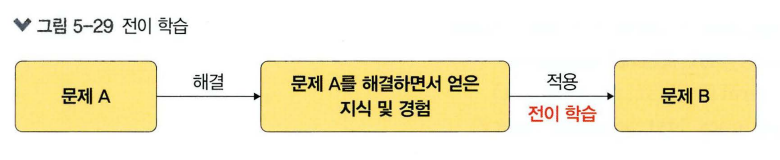

### 5.3.1 특성 추출 기법

- 사전 훈련된 모델을 가져와 **마지막 완전연결층만 새로 만들고, 그 부분만 학습**함
- 구성
  - **합성곱층**(합성곱층 + 풀링층): 가중치 고정
  - **데이터 분류기**(완전연결층): 추출된 특성으로 클래스를 분류, 이 부분만 학습

특성 추출 = 합성곱층 고정 + 분류기만 학습

####자주 나오는 함수
- Resize : 이미지 크기 조정
- RandomResizedCrop : 무작위 자르기 (데이터 증강)
- RandomHorizontalFlip : 좌우 반전
- ToTensor : 텐서 변환
- ImageFolder : 이미지 데이터셋 불러오기
- DataLoader : 배치 단위로 데이터 불러오기
- iter() : 반복자 생성
- next() : 다음 데이터 반환
- np.transpose() : 배열 차원 순서 변경

### 5.3.2 미세 조정 기법

사전 학습된 모델의 가중치를 목적에 맞게 추가 학습하여 성능을 높이는 기법

- 특성 추출(Feature Extraction): 사전 학습된 모델의 가중치를 그대로 사용하고, 데이터 분류기만 학습한다.
- 미세 조정(Fine-tuning): 사전 학습된 모델의 합성곱층과 데이터 분류기 일부 또는 전체의 가중치를 업데이트하여 새로운 데이터에 맞게 재학습한다.

#### 데이터셋 크기와 사전 학습 모델의 유사성에 따른 전략

| 데이터셋 크기 | 사전 학습 모델과의 유사성 | 학습 전략             |
| ------- | -------------- | ----------------- |
| 큼       | 낮음             | 모델 전체 재학습         |
| 큼       | 높음             | 합성곱층 뒷부분 + 분류기 학습 |
| 작음      | 낮음             | 합성곱층 일부 + 분류기 학습  |
| 작음      | 높음             | 데이터 분류기만 학습       |

#### 핵심 개념

- 데이터가 많고 기존 모델과 차이가 클수록 더 많은 계층을 재학습한다.
- 데이터가 적고 기존 모델과 유사할수록 적은 계층만 재학습한다.
- 데이터가 적은데 너무 많은 계층을 학습하면 과적합(Overfitting)이 발생할 수 있다.
- 미세 조정은 연산량이 많으므로 CPU보다 GPU 사용을 권장한다.


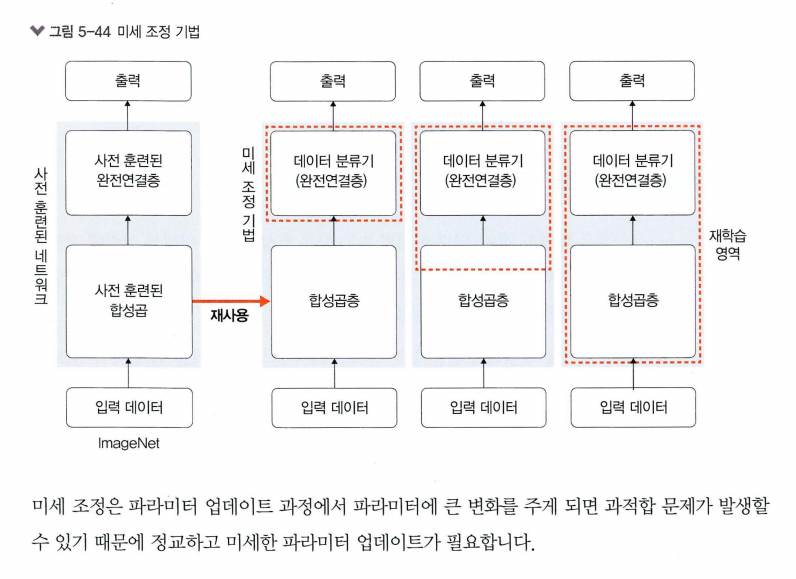

In [ ]:
import os
import time
import copy
import glob
import cv2
import shutil

import torch
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt

In [ ]:
!git clone --depth 1 --filter=blob:none --sparse https://github.com/gilbutITbook/080289.git
%cd 080289
!git sparse-checkout set chap05/data/catanddog
%cd ..

Cloning into '080289'...
remote: Enumerating objects: 51, done.
remote: Counting objects: 100% (51/51), done.
remote: Compressing objects: 100% (47/47), done.
remote: Total 51 (delta 2), reused 42 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (51/51), 57.21 KiB | 11.44 MiB/s, done.
Resolving deltas: 100% (2/2), done.
remote: Enumerating objects: 1, done.
remote: Counting objects: 100% (1/1), done.
remote: Total 1 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (1/1), 1.04 KiB | 1.04 MiB/s, done.
/content/080289
remote: Enumerating objects: 489, done.
remote: Counting objects: 100% (489/489), done.
remote: Compressing objects: 100% (489/489), done.
remote: Total 489 (delta 0), reused 488 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (489/489), 33.70 MiB | 16.85 MiB/s, done.
Updating files: 100% (489/489), done.
/content


In [ ]:
data_path = '080289/chap05/data/catanddog/train'

transform = transforms.Compose(
                [
                    transforms.Resize([256, 256]),
                    transforms.RandomResizedCrop(224),
                    transforms.RandomHorizontalFlip(),
                    transforms.ToTensor()
])
train_dataset = torchvision.datasets.ImageFolder(
                data_path,
                transform=transform
)
train_loader = torch.utils.data.DataLoader(
               train_dataset,
               batch_size=32,
               num_workers=8,
               shuffle=True
)

print(len(train_dataset))

385


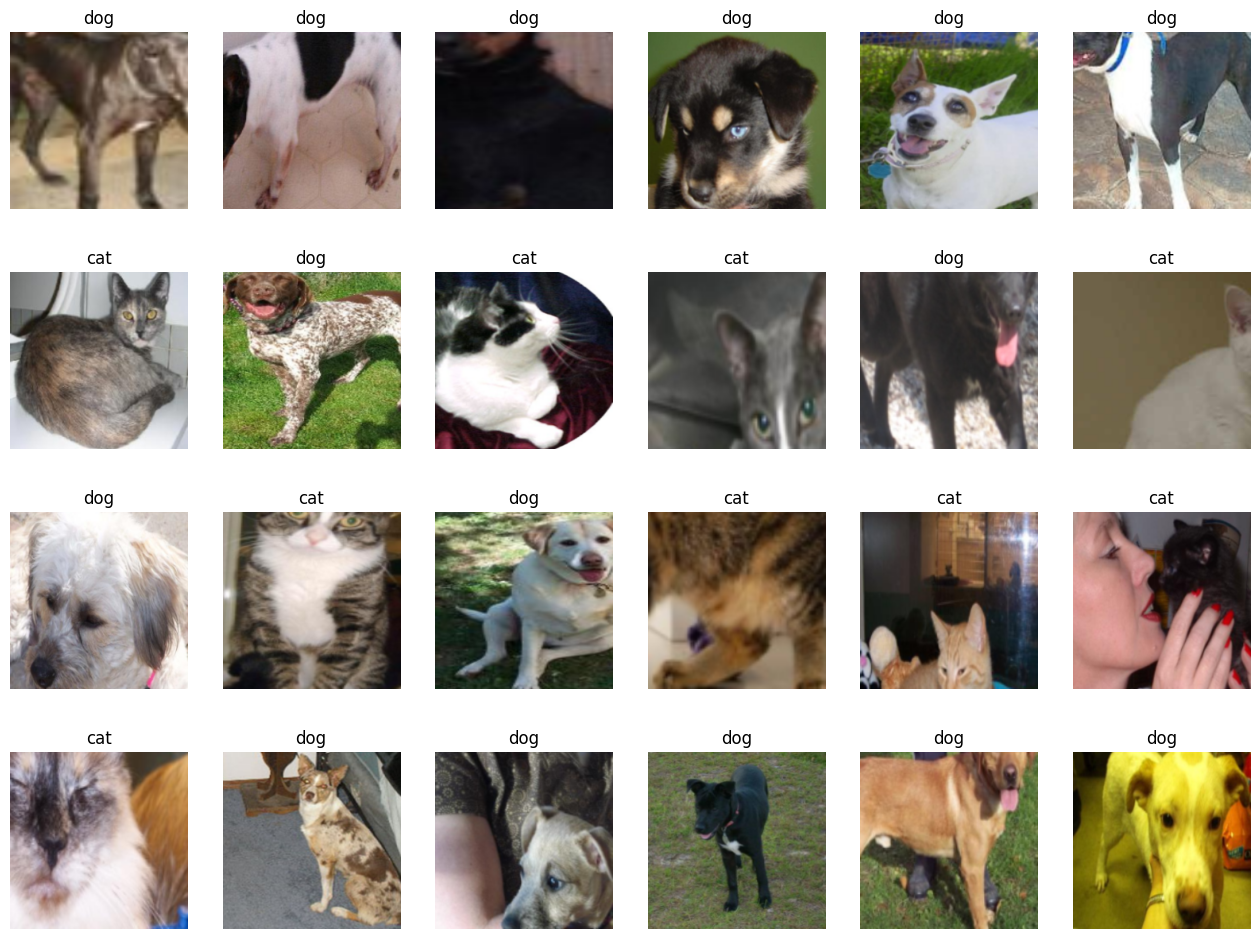

In [ ]:
import numpy as np
samples, labels = next(iter(train_loader))
classes = {0:'cat', 1:'dog'}
fig = plt.figure(figsize=(16,24))
for i in range(24):
    a = fig.add_subplot(4,6,i+1)
    a.set_title(classes[labels[i].item()])
    a.axis('off')
    a.imshow(np.transpose(samples[i].numpy(), (1,2,0)))
plt.subplots_adjust(bottom=0.2, top=0.6, hspace=0)

In [ ]:
resnet18 = models.resnet18(pretrained=True)  # pretrained=True는 사전 학습된 가중치를 사용하겠다는 의미

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 347MB/s]


In [ ]:
def set_parameter_requires_grad(model, feature_extracting=True):
    if feature_extracting:
        for param in model.parameters():
            param.requires_grad = False

set_parameter_requires_grad(resnet18)

In [ ]:
resnet18.fc = nn.Linear(512, 2)

In [ ]:
for name, param in resnet18.named_parameters():
    if param.requires_grad:
        print(name, param.data)

fc.weight tensor([[-0.0437,  0.0343,  0.0104,  ..., -0.0029, -0.0303, -0.0338],
        [-0.0425,  0.0341,  0.0271,  ..., -0.0302,  0.0131, -0.0385]])
fc.bias tensor([-0.0325,  0.0327])


In [ ]:
model = models.resnet18(pretrained=True)

for param in model.parameters():
    param.requires_grad = False

model.fc = torch.nn.Linear(512, 2)
for param in model.fc.parameters():
    param.requires_grad = True

optimizer = torch.optim.Adam(model.fc.parameters())
cost = torch.nn.CrossEntropyLoss()
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [ ]:
def train_model(model, dataloaders, criterion, optimizer, device, num_epochs=13,
                is_train=True):
    since = time.time()
    acc_history = []
    loss_history = []
    best_acc = 0.0

    for epoch in range(num_epochs):
        print('Epoch {}/{}'.format(epoch, num_epochs-1))
        print('-' * 10)

        running_loss = 0.0
        running_corrects = 0

        for inputs, labels in dataloaders:
            inputs = inputs.to(device)
            labels = labels.to(device)

            model.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            _, preds = torch.max(outputs, 1)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

        epoch_loss = running_loss / len(dataloaders.dataset)
        epoch_acc = running_corrects.double() / len(dataloaders.dataset)

        print('Loss: {:.4f} Acc: {:.4f}'.format(epoch_loss, epoch_acc))

        if epoch_acc > best_acc:
            best_acc = epoch_acc

        acc_history.append(epoch_acc.item())
        loss_history.append(epoch_loss)
        torch.save(model.state_dict(), os.path.join('080289/chap05/data/catanddog/',
                   '{0:0=2d}.pth'.format(epoch)))
        print()

    time_elapsed = time.time() - since
    print('Training complete in {:.0f}m {:.0f}s'.format(time_elapsed // 60,
          time_elapsed % 60))
    print('Best Acc: {:4f}'.format(best_acc))
    return acc_history, loss_history

In [ ]:
params_to_update = []
for name, param in resnet18.named_parameters():
    if param.requires_grad == True:
        params_to_update.append(param)
        print("\t", name)

optimizer = optim.Adam(params_to_update)

	 fc.weight
	 fc.bias


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
criterion = nn.CrossEntropyLoss()
train_acc_hist, train_loss_hist = train_model(resnet18, train_loader, criterion,
                                              optimizer, device)

Epoch 0/12
----------
Loss: 0.3589 Acc: 0.8338

Epoch 1/12
----------
Loss: 0.2665 Acc: 0.8805

Epoch 2/12
----------
Loss: 0.2289 Acc: 0.9325

Epoch 3/12
----------
Loss: 0.2286 Acc: 0.9143

Epoch 4/12
----------
Loss: 0.2113 Acc: 0.9273

Epoch 5/12
----------
Loss: 0.2077 Acc: 0.9195

Epoch 6/12
----------
Loss: 0.1859 Acc: 0.9325

Epoch 7/12
----------
Loss: 0.1795 Acc: 0.9325

Epoch 8/12
----------
Loss: 0.1790 Acc: 0.9247

Epoch 9/12
----------
Loss: 0.1631 Acc: 0.9403

Epoch 10/12
----------
Loss: 0.1608 Acc: 0.9455

Epoch 11/12
----------
Loss: 0.1693 Acc: 0.9299

Epoch 12/12
----------
Loss: 0.1770 Acc: 0.9221

Training complete in 0m 4s
Best Acc: 0.945455


In [ ]:
test_path = '080289/chap05/data/catanddog/test'

transform = transforms.Compose(
                [
                    transforms.Resize(224),
                    transforms.CenterCrop(224),
                    transforms.ToTensor(),
])
test_dataset = torchvision.datasets.ImageFolder(
    root=test_path,
    transform=transform
)
test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=32,
    num_workers=1,
    shuffle=True
)

print(len(test_dataset))

98


In [ ]:
def eval_model(model, dataloaders, device):
    since = time.time()
    acc_history = []
    best_acc = 0.0

    saved_models = glob.glob('080289/chap05/data/catanddog/' + '*.pth')
    saved_models.sort()
    print('saved_model', saved_models)

    for model_path in saved_models:
        print('Loading model', model_path)

        model.load_state_dict(torch.load(model_path))
        model.eval()
        model.to(device)
        running_corrects = 0

        for inputs, labels in dataloaders:
            inputs = inputs.to(device)
            labels = labels.to(device)

            with torch.no_grad():
                outputs = model(inputs)

            _, preds = torch.max(outputs.data, 1)
            preds[preds >= 0.5] = 1
            preds[preds < 0.5] = 0
            running_corrects += preds.eq(labels).int().sum()

        epoch_acc = running_corrects.double() / len(dataloaders.dataset)
        print('Acc: {:.4f}'.format(epoch_acc))

        if epoch_acc > best_acc:
            best_acc = epoch_acc
        acc_history.append(epoch_acc.item())
        print()

    time_elapsed = time.time() - since
    print('Validation complete in {:.0f}m {:.0f}s'.format(time_elapsed // 60,
          time_elapsed % 60))
    print('Best Acc: {:4f}'.format(best_acc))

    return acc_history

In [ ]:
val_acc_hist = eval_model(resnet18, test_loader, device)

saved_model ['080289/chap05/data/catanddog/00.pth', '080289/chap05/data/catanddog/01.pth', '080289/chap05/data/catanddog/02.pth', '080289/chap05/data/catanddog/03.pth', '080289/chap05/data/catanddog/04.pth', '080289/chap05/data/catanddog/05.pth', '080289/chap05/data/catanddog/06.pth', '080289/chap05/data/catanddog/07.pth', '080289/chap05/data/catanddog/08.pth', '080289/chap05/data/catanddog/09.pth', '080289/chap05/data/catanddog/10.pth', '080289/chap05/data/catanddog/11.pth', '080289/chap05/data/catanddog/12.pth']
Loading model 080289/chap05/data/catanddog/00.pth
Acc: 0.9082

Loading model 080289/chap05/data/catanddog/01.pth
Acc: 0.9184

Loading model 080289/chap05/data/catanddog/02.pth
Acc: 0.9184

Loading model 080289/chap05/data/catanddog/03.pth
Acc: 0.9286

Loading model 080289/chap05/data/catanddog/04.pth
Acc: 0.9286

Loading model 080289/chap05/data/catanddog/05.pth
Acc: 0.9388

Loading model 080289/chap05/data/catanddog/06.pth
Acc: 0.9388

Loading model 080289/chap05/data/catand

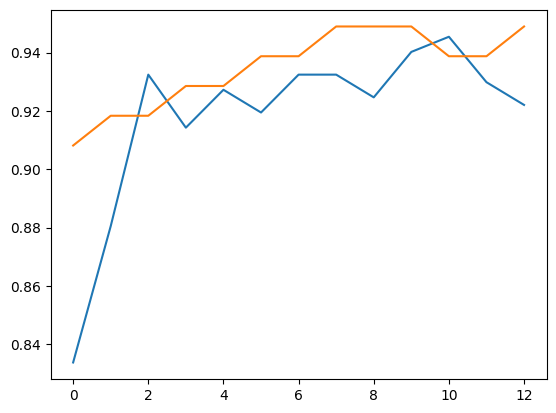

In [ ]:
plt.plot(train_acc_hist)
plt.plot(val_acc_hist)
plt.show()

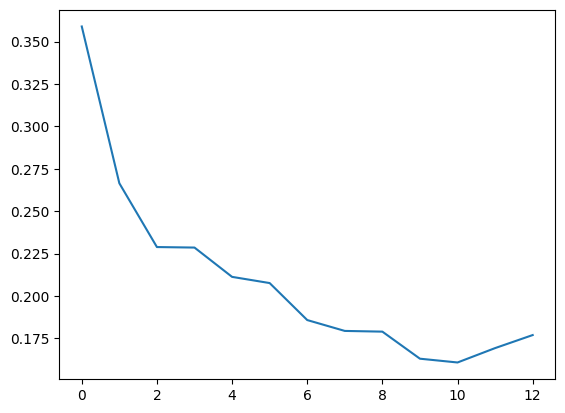

In [ ]:
plt.plot(train_loss_hist)
plt.show()

In [ ]:
def im_convert(tensor):
    image = tensor.clone().detach().numpy()
    image = image.transpose(1, 2, 0)
    image = image * (np.array((0.5,0.5,0.5)) + np.array((0.5,0.5,0.5)))
    image = image.clip(0, 1)
    return image

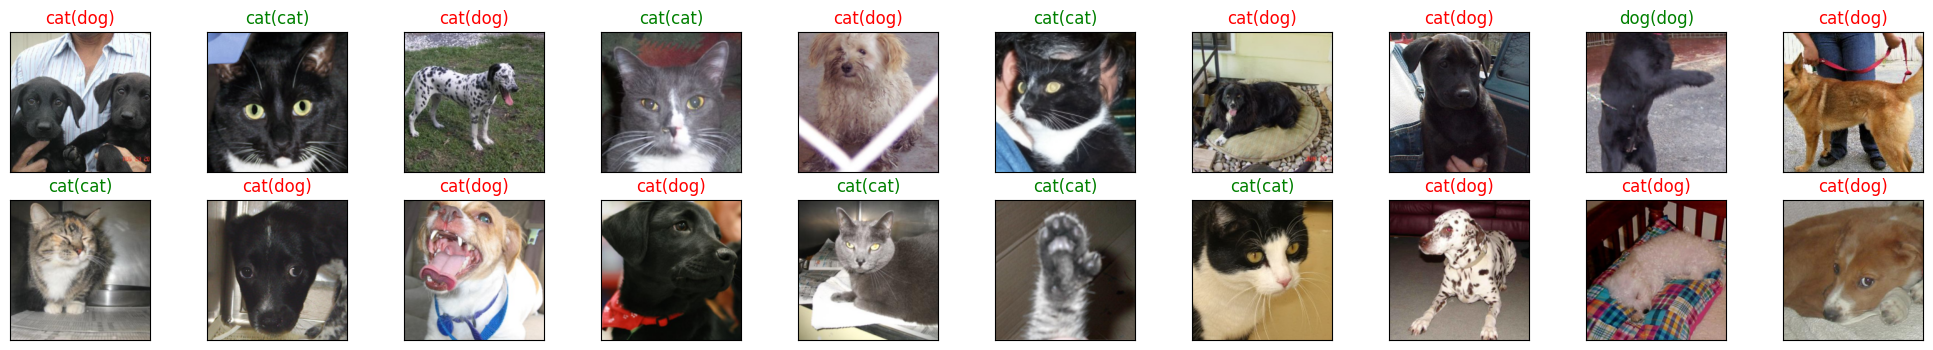

<Figure size 640x480 with 0 Axes>

In [ ]:
classes = {0:'cat', 1:'dog'}

dataiter = iter(test_loader)
images, labels = next(dataiter)
output = model(images)
_, preds = torch.max(output, 1)

fig = plt.figure(figsize=(25,4))
for idx in np.arange(20):
    ax = fig.add_subplot(2, 10, idx+1, xticks=[], yticks=[])
    plt.imshow(im_convert(images[idx]))
    a.set_title(classes[labels[i].item()])
    ax.set_title("{}({})".format(str(classes[preds[idx].item()]), str(classes[labels[idx].item()])), color=("green" if preds[idx]==labels[idx] else "red"))
plt.show()
plt.subplots_adjust(bottom=0.2, top=0.6, hspace=0)